# Verification: Cooperative Bivalent Binding (Posner et al., 2004)

`blbr_cooperativity_posner2004.bngl` is the bivalent-ligand (23G3) / bivalent-receptor
(IgE-FcεRI) model with negative cooperativity, at the "-rings" parameters of Table 1 of
Posner et al. (2004) (J2 = 0: linear chains only). It is verified against the equilibrium
theory of Wofsy and Goldstein (1987), solved independently with `scipy.optimize`, and every
comparison is asserted against a tolerance stated with its source of error. All simulations
are stock BioNetGen (BNG2.pl) driving its NFsim.

1. **Regression.** The unmodified files (seed 42) reproduce the committed `reference/` scans.
2. **Theory.** An ensemble of the file's own 20-dose `parameter_scan`, each replicate with a
   distinct seed in place of the pinned `seed=>42`, against the theory's fraction of 23G3
   epitopes bound, $q$, at every dose.
3. **The same-complex (`-bscb`) question, settled by measurement.** The "-rings" model has no
   cyclic aggregates, so a crosslinking rule must not bind two sites of one chain. The file
   carries `complex=>1` and no `-bscb`; section 4 shows what NFsim does with that, counts
   cycles in final species lists directly, and measures whether turning the block off changes
   $q$ at the file's parameters.

The `_rings` variant is run only for its regression baseline (section 5); it is not verified
here.

In [1]:
import os, re, shutil, subprocess, tempfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

HERE = Path.cwd()
STEM = "blbr_cooperativity_posner2004"
MODEL = (HERE / f"{STEM}.bngl").read_text()
WORKERS = int(os.environ.get("BNGLM_WORKERS", "2"))   # concurrent BNG2.pl runs


def find_bionetgen():
    """BNG2.pl from $BNG2_PL or $BNGPATH, then BNG2.pl on PATH, then the `bionetgen` CLI."""
    for cand in (os.environ.get("BNG2_PL"),
                 str(Path(os.environ["BNGPATH"]) / "BNG2.pl") if os.environ.get("BNGPATH") else None,
                 shutil.which("BNG2.pl")):
        if cand and Path(cand).is_file():
            return str(Path(cand).absolute()), False
    cli = shutil.which("bionetgen")
    if cli:
        return cli, True
    raise FileNotFoundError("BioNetGen not found: set BNG2_PL (or BNGPATH) to a BioNetGen 2.9.3 "
                            "BNG2.pl, or put the bionetgen CLI on PATH.")


BNG, USE_CLI = find_bionetgen()
print("BioNetGen:", BNG)
TMP = Path(tempfile.mkdtemp(prefix="nfruns_", dir=HERE))   # removed at the end


def cycle_rank(species_text):
    """Independent cycles summed over the final complexes: bonds - molecules + 1 per complex."""
    total = 0
    for line in species_text.splitlines():
        if line.strip() and not line.startswith("#"):
            pat, n = line.rsplit(None, 1)
            total += (len(set(re.findall(r"!(\d+)", pat))) - len(pat.split(".")) + 1) * int(float(n))
    return total


def run(text, tag, stem=STEM):
    """Run one model text with BioNetGen in its own directory; return what it wrote."""
    d = TMP / tag
    d.mkdir()
    f = d / f"{stem}.bngl"
    f.write_text(text)
    cmd = ([BNG, "run", "-i", str(f), "-o", str(d)] if USE_CLI
           else ["perl", BNG, "--outdir", str(d), str(f)])
    r = subprocess.run(cmd, capture_output=True, text=True, cwd=d)
    assert r.returncode == 0, r.stdout[-3000:] + r.stderr[-3000:]
    log = r.stdout + r.stderr
    out = {"null": [int(x) for x in re.findall(r"Null events:\s*(\d+)", log)]}
    scan = d / f"{stem}_scan.scan"
    if scan.exists():
        out["scan_text"] = scan.read_text()
        out["scan"] = np.loadtxt(scan, comments="#")
    sp = sorted(d.glob("*.species"))
    if sp:
        out["cycles"] = cycle_rank(sp[0].read_text())
        out["final"] = np.loadtxt(next(d.glob("*.gdat")), comments="#")[-1]
    shutil.rmtree(d)
    return out


KEY = "gml=>1000000,seed=>42})"
assert MODEL.count(KEY) == 1


def with_seed(seed, extra=""):
    """The file verbatim, with the scan's pinned seed replaced (extra edits the NFsim flags)."""
    text = MODEL.replace(KEY, f"gml=>1000000,seed=>{seed}}})")
    if extra:
        assert text.count("complex=>1,") == 1
        text = text.replace("complex=>1,", extra)
    return text


def one_dose(AT, seed, flags):
    """The file's model block verbatim, with one simulate at one dose (final species kept)."""
    body = MODEL[: MODEL.index("begin actions")]
    return (body + f'begin actions\nsetParameter("AT_nM",{AT})\n'
            f'simulate({{method=>"nf",suffix=>"one",t_start=>0,t_end=>10,n_steps=>1,{flags},'
            f'gml=>1000000,seed=>{seed}}})\nend actions\n')


def run_many(texts_tags):
    with ThreadPoolExecutor(WORKERS) as ex:
        return list(ex.map(lambda tt: run(*tt), texts_tags))


RT_sim = 3e5 * 0.003   # receptors in the simulation volume (R_per_cell * f) = 900

BioNetGen: /vast/home/wish/wt/scratch/bng-loader/BioNetGen-2.9.3/BNG2.pl


## 1. Regression: the unmodified files reproduce `reference/`

Each action pins `seed=>42`, so a fresh run of each file as committed must reproduce its
committed `.scan` exactly.

In [2]:
for stem in (STEM, f"{STEM}_rings"):
    r = run((HERE / f"{stem}.bngl").read_text(), f"ref_{stem}", stem)
    same = r["scan_text"] == (HERE / "reference" / f"{stem}_scan.scan").read_text()
    print(f"fresh seed-42 scan of {stem}.bngl == reference/{stem}_scan.scan: {same}")
    assert same, f"the pinned seed no longer reproduces reference/{stem}_scan.scan"

fresh seed-42 scan of blbr_cooperativity_posner2004.bngl == reference/blbr_cooperativity_posner2004_scan.scan: True


fresh seed-42 scan of blbr_cooperativity_posner2004_rings.bngl == reference/blbr_cooperativity_posner2004_rings_scan.scan: True


## Wofsy–Goldstein Equilibrium Theory (no rings)

From Wofsy & Goldstein (1987), Mol Immunol 24:151–161.

**Dimensionless quantities** (eqs 4a–7):
- $c = 2KC$ (free ligand, $C$ in nM, $K$ in /nM)
- $k = 2K_x X_T$ (cross-linking; equals $K_x S_T$ since $S_T = 2X_T$)
- $\sigma = H$ (cooperativity)
- $\delta = ck\sigma / (1 + 2c + c^2\sigma)$
- $\eta = (1 + c\sigma)^2 / [\sigma(1 + 2c + c^2\sigma)]$

**IgE conservation** (eq 10, $J_n = 0$):
$$1 = w(1-\eta) + \frac{\eta w}{(1-\delta w)^2}$$

**Fraction of epitopes bound** (eq 17, $c_m = 0$):
$$q = 1 - \frac{w(1+c)}{1+2c+c^2\sigma} - \frac{\eta\delta w^2}{(1+c\sigma)(1-\delta w)}$$

**Ligands bound per IgE** (eq 15, $c_m = 0$):
$$c_b = 1 + \frac{w}{1-\delta w}\left[\frac{2c(1+c\sigma)}{1+2c+c^2\sigma} - 1\right]
      + \frac{(1-\eta)\delta w^2}{1-\delta w}$$

**Ligand conservation:**
$$A_T = C_{\text{free}} + C_{RT} \cdot c_b$$
where $C_{RT} = C \cdot R_T$ in nM (= $C_{ST}/2$).

In [3]:
def solve_wofsy_equilibrium(AT_nM, K, k, sigma, CRT):
    """
    Solve Wofsy-Goldstein equilibrium (no rings, no monovalent ligand).
    
    Parameters
    ----------
    AT_nM : float
        Total antibody concentration (nM).
    K : float
        Single-site binding constant (/nM).
    k : float
        Dimensionless cross-linking parameter (= KxST).
    sigma : float
        Cooperativity parameter (= H).
    CRT : float
        C * RT in nM (receptor concentration in bulk).
    
    Returns
    -------
    C_free : float  — free ligand concentration (nM)
    w : float       — fraction of unaggregated IgE
    q : float       — fraction of epitopes bound
    c_b : float     — ligands bound per IgE
    """
    if AT_nM < 1e-15:
        return 0.0, 1.0, 0.0, 0.0
    
    def _derived(c):
        """Compute delta, eta from dimensionless free ligand c."""
        D = 1 + 2*c + c**2 * sigma
        delta = c * k * sigma / D if D > 0 else 0.0
        eta = (1 + c*sigma)**2 / (sigma * D) if D > 0 else 1.0/sigma
        return delta, eta
    
    def _solve_w(c):
        """Solve eq 10 for w given c (J_n = 0)."""
        delta, eta = _derived(c)
        if delta < 1e-15:
            # delta -> 0: eq 10 becomes 1 = w, so w = 1
            return 1.0
        def eq10(w):
            dw = delta * w
            if dw >= 1:
                return -1e10
            return w*(1 - eta) + eta*w/(1 - dw)**2 - 1
        w_max = min(1.0, (1 - 1e-8)/delta)
        try:
            return brentq(eq10, 1e-15, w_max, xtol=1e-14)
        except ValueError:
            return 1.0
    
    def _compute_q(c, w):
        """Fraction of epitopes bound (eq 17, c_m = 0)."""
        delta, eta = _derived(c)
        D = 1 + 2*c + c**2*sigma
        dw = delta * w
        term1 = w * (1 + c) / D
        term2 = eta * delta * w**2 / ((1 + c*sigma) * (1 - dw)) if (1 - dw) > 1e-15 else 0.0
        return 1 - term1 - term2
    
    def _compute_cb(c, w):
        """Ligands bound per IgE (eq 15, c_m = 0)."""
        delta, eta = _derived(c)
        D = 1 + 2*c + c**2*sigma
        dw = delta * w
        if abs(1 - dw) < 1e-15:
            return 0.0
        bracket = 2*c*(1 + c*sigma)/D - 1
        return 1 + w/(1 - dw) * bracket + (1 - eta)*delta*w**2/(1 - dw)
    
    def _AT_from_Cfree(C_free):
        """Compute total Ab from free Ab via ligand conservation."""
        c = 2 * K * C_free
        w = _solve_w(c)
        cb = _compute_cb(c, w)
        return C_free + CRT * cb
    
    # Find C_free in [0, AT] such that _AT_from_Cfree(C_free) = AT_nM
    f = lambda Cf: _AT_from_Cfree(Cf) - AT_nM
    try:
        C_free = brentq(f, 0, AT_nM, xtol=1e-14)
    except ValueError:
        C_free = AT_nM
    
    c = 2 * K * C_free
    w = _solve_w(c)
    q = _compute_q(c, w)
    cb = _compute_cb(c, w)
    return C_free, w, q, cb

print('Solver defined.')

Solver defined.


## 2. Theory at the file's parameters

Table 1, "-rings" column: $K = 0.098$ /nM, $K_x S_T = 2.5$, $H = 0.39$. The receptor
concentration in the assay is fixed by the experimental conditions the file encodes,
$3\times10^5$ FcεRI per cell at $10^6$ cells/mL: $C R_T = 3\times10^5 \cdot 10^9 / N_A$ =
0.49816 nM (the curated notebook rounded $C S_T$ to 1.0 nM, a 0.4% difference that is now
removed).

In [4]:
NA = 6.02214076e23
CRT = 3e5 * 1e9 / NA * 1e9          # nM
P_NORINGS = dict(K=0.098, k=2.5, sigma=0.39)
print(f"C*R_T = {CRT:.5f} nM")
AT_theory = np.logspace(np.log10(0.01), np.log10(1000), 200)
q_theory_curve = np.array([solve_wofsy_equilibrium(a, P_NORINGS["K"], P_NORINGS["k"],
                                                   P_NORINGS["sigma"], CRT)[2] for a in AT_theory])

C*R_T = 0.49816 nM


## 3. NFsim ensemble against the theory

`N_SEEDS` replicates of the file's own scan (20 doses, 0.03 to 100 nM, each run to $t = 10$ s,
about 100 relaxation times at $k_r = 10$ /s), seeds 1..N, one seed per replicate. For each
dose the replicate values of $q = (\mathrm{Obs\_R\_l1\_bound} + \mathrm{Obs\_R\_l2\_bound}) / 2R_T$
give a mean and a standard error. Tolerance at every dose:
$|\bar q_\mathrm{NF} - q_\mathrm{theory}| \le 3\,\mathrm{SE} + 0.002$. The 3 SE is Monte-Carlo
error (the maximum over 20 doses of a standard normal is about 2.2, so 3 leaves margin). The
0.002 is the theory's own approximation: it is the large-system equilibrium, and the model
has 1800 receptor sites, so finite-size corrections to a fraction are of order
$1/1800 = 0.0006$; 0.002 is three times that. A pooled test catches a systematic offset the
per-dose bound might not: $\sum z/\sqrt{20}$ must lie within $\pm 3$.

In [5]:
N_SEEDS = int(os.environ.get("POSNER_N_SEEDS", "120"))
ens = run_many([(with_seed(s), f"seed{s}") for s in range(1, N_SEEDS + 1)])
AT = ens[0]["scan"][:, 0]
assert all(np.array_equal(e["scan"][:, 0], AT) for e in ens)
assert len({e["scan_text"] for e in ens}) == N_SEEDS, "two seeds gave the same scan"
Q = np.array([(e["scan"][:, 2] + e["scan"][:, 3]) / (2 * RT_sim) for e in ens])
qm, qse = Q.mean(axis=0), Q.std(axis=0, ddof=1) / np.sqrt(N_SEEDS)
q_th = np.array([solve_wofsy_equilibrium(a, P_NORINGS["K"], P_NORINGS["k"], P_NORINGS["sigma"], CRT)[2]
                 for a in AT])
DELTA = 0.002
tol = 3 * qse + DELTA
z = (qm - q_th) / qse
print(f"{N_SEEDS} replicates, distinct seeds 1..{N_SEEDS}, all scans distinct\n")
print(f"{'AT (nM)':>9s} {'q NFsim':>16s} {'q theory':>9s} {'diff':>8s} {'tol':>7s}     z")
for a, m, s, th, tl, zz in zip(AT, qm, qse, q_th, tol, z):
    print(f"{a:9.4f} {m:9.4f} +- {s:.4f} {th:9.4f} {m - th:+8.4f} {tl:7.4f} {zz:+6.2f}")
zpool = z.sum() / np.sqrt(len(z))
print(f"\nmax |diff| = {np.abs(qm - q_th).max():.4f}; max |z| = {np.abs(z).max():.2f}; pooled z = {zpool:+.2f}")
assert np.all(np.abs(qm - q_th) <= tol), "NFsim q outside 3 SE + 0.002 of the theory at some dose"
assert abs(zpool) < 3
print("theory: PASS")

120 replicates, distinct seeds 1..120, all scans distinct

  AT (nM)          q NFsim  q theory     diff     tol     z
   0.0300    0.0138 +- 0.0003    0.0139  -0.0001  0.0028  -0.29
   0.0460    0.0215 +- 0.0003    0.0210  +0.0005  0.0030  +1.44
   0.0705    0.0311 +- 0.0005    0.0315  -0.0003  0.0034  -0.73
   0.1080    0.0469 +- 0.0005    0.0467  +0.0003  0.0035  +0.50
   0.1655    0.0681 +- 0.0005    0.0682  -0.0001  0.0036  -0.20
   0.2536    0.0961 +- 0.0006    0.0977  -0.0016  0.0038  -2.61
   0.3887    0.1369 +- 0.0007    0.1361  +0.0008  0.0041  +1.11
   0.5957    0.1838 +- 0.0008    0.1838  -0.0000  0.0044  -0.00
   0.9129    0.2410 +- 0.0009    0.2395  +0.0015  0.0047  +1.62
   1.3991    0.3003 +- 0.0010    0.3013  -0.0010  0.0050  -1.00
   2.1442    0.3677 +- 0.0010    0.3667  +0.0010  0.0051  +0.93
   3.2861    0.4340 +- 0.0009    0.4340  -0.0000  0.0048  -0.04
   5.0361    0.5022 +- 0.0009    0.5019  +0.0003  0.0047  +0.35
   7.7181    0.5702 +- 0.0010    0.5696  +0.0006 

## 4. The same-complex question

**What NFsim does with this file.** The scan passes `complex=>1`, so BNG2.pl gives NFsim
`-cb`. In NFsim 1.14.3 `-cb` alone already blocks a bimolecular rule from binding two sites
of one complex (the firing becomes a null event), exactly as under `-bscb`: the same seed with
`param=>"-bscb"` added must give a byte-identical scan, with null events recorded (so the
identity is not vacuous). In this model the only same-complex candidates are the four
cooperative crosslinking rules, whose receptor already carries a ligand: the free arm at one
end of a chain meeting the free epitope at the other end, which would close a ring.

**Acyclicity, counted directly.** Single runs at the dose of maximal crosslinking
(AT = 5.036 nM, scan point 13) keep the final species list; a complex with $m$ molecules and
$b$ bonds has $b - m + 1$ independent cycles, and the blocked runs must sum to zero.
**Control:** with `complex=>0` (no complex bookkeeping, no block) NFsim does close rings; the
control runs must show cycles and no null events, which shows the count can fail.

**Does blocking matter at the file's parameters?** The scan ensemble repeated with
`complex=>0` (seeds 1001..), against the blocked ensemble of section 3, dose by dose. The
assertion is that it does not, so that the statement in `metadata.yaml` is a measurement:
every dose within $|z| < 3.5$ (the family-wise 1% bound for the maximum of 20 standard
normals, $\Phi^{-1}(1 - 0.01/40) = 3.5$) and the pooled $\sum z/\sqrt{20}$ within $\pm 3$.

In [6]:
idn = run_many([(with_seed(s, 'complex=>1,param=>"-bscb",'), f"bscb{s}") for s in (1, 2, 3)])
identical = all(i["scan_text"] == ens[s - 1]["scan_text"] for i, s in zip(idn, (1, 2, 3)))
nulls = [sum(i["null"]) for i in idn]
print(f"seeds 1-3, scan with -cb -bscb == scan with -cb: {identical}; null events per scan: {nulls} "
      f"(over 20 doses; -cb runs: {[sum(ens[s - 1]['null']) for s in (1, 2, 3)]})")
assert identical and all(x > 0 for x in nulls) and len(idn[0]["null"]) == len(AT)

N_ONE = 50
one_b = run_many([(one_dose(AT[12], s, "complex=>1"), f"one_cb{s}") for s in range(1, N_ONE + 1)])
one_u = run_many([(one_dose(AT[12], s, "complex=>0"), f"one_nocb{s}") for s in range(1, N_ONE + 1)])
cyc_b = sum(o["cycles"] for o in one_b)
cyc_u = sum(o["cycles"] for o in one_u)
print(f"\nAT = {AT[12]:.4f} nM, {N_ONE} seeds: blocked: {cyc_b} cycles, {sum(sum(o['null']) for o in one_b)} null events; "
      f"complex=>0: {cyc_u} cycles in {sum(o['cycles'] > 0 for o in one_u)} final states, "
      f"{sum(sum(o['null']) for o in one_u)} null events")
assert cyc_b == 0
assert cyc_u > 0 and sum(sum(o["null"]) for o in one_u) == 0

unb = run_many([(with_seed(s, "complex=>0,"), f"nocb{s}") for s in range(1001, 1001 + N_SEEDS)])
QU = np.array([(e["scan"][:, 2] + e["scan"][:, 3]) / (2 * RT_sim) for e in unb])
du = QU.mean(axis=0) - qm
seu = np.hypot(QU.std(axis=0, ddof=1), Q.std(axis=0, ddof=1)) / np.sqrt(N_SEEDS)
zu = du / seu
print(f"\nunblocked - blocked q over {N_SEEDS} + {N_SEEDS} replicates: max |diff| {np.abs(du).max():.4f}, "
      f"max |z| {np.abs(zu).max():.2f}, pooled z {zu.sum() / np.sqrt(len(zu)):+.2f}")
assert np.all(np.abs(zu) < 3.5) and abs(zu.sum() / np.sqrt(len(zu))) < 3
print("blocking same-complex binding does not change q at the file's parameters")

seeds 1-3, scan with -cb -bscb == scan with -cb: True; null events per scan: [219, 204, 203] (over 20 doses; -cb runs: [219, 204, 203])



AT = 5.0361 nM, 50 seeds: blocked: 0 cycles, 1061 null events; complex=>0: 3 cycles in 3 final states, 0 null events



unblocked - blocked q over 120 + 120 replicates: max |diff| 0.0027, max |z| 2.99, pooled z -1.29
blocking same-complex binding does not change q at the file's parameters


## 5. Figure

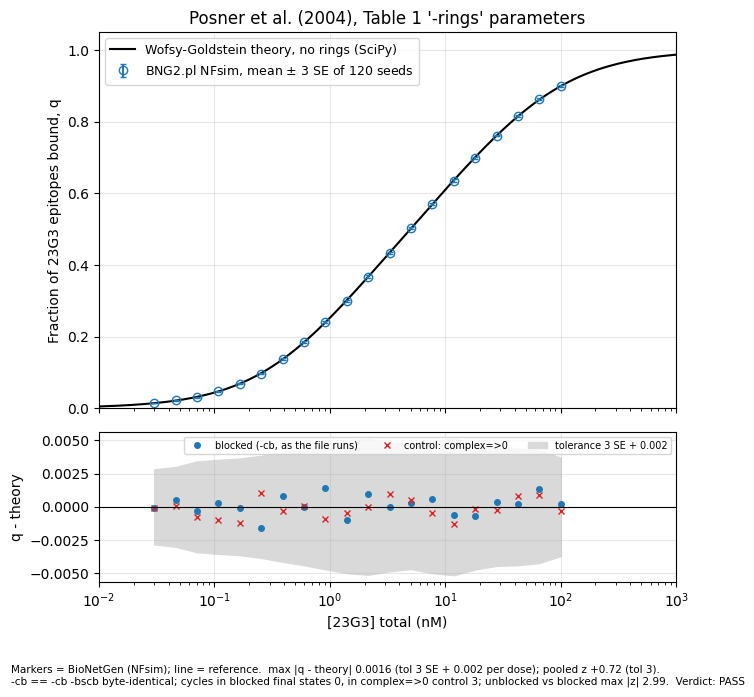

Saved verify_posner2004.png; removed nfruns_4pu2j_h4


In [7]:
fig, (ax, axr) = plt.subplots(2, 1, figsize=(7, 6.5), height_ratios=[3, 1.2], sharex=True)
ax.plot(AT_theory, q_theory_curve, "-", color="k", lw=1.5, label="Wofsy-Goldstein theory, no rings (SciPy)")
ax.errorbar(AT, qm, yerr=3 * qse, fmt="o", mfc="none", ms=6, color="tab:blue", capsize=2,
            label=f"BNG2.pl NFsim, mean $\\pm$ 3 SE of {N_SEEDS} seeds")
ax.set_xscale("log"); ax.set_xlim(0.01, 1000); ax.set_ylim(0, 1.05)
ax.set_ylabel("Fraction of 23G3 epitopes bound, q"); ax.grid(True, alpha=0.3); ax.legend(fontsize=9, loc="upper left")
ax.set_title("Posner et al. (2004), Table 1 '-rings' parameters")
axr.plot(AT, qm - q_th, "o", color="tab:blue", ms=4, label="blocked (-cb, as the file runs)")
axr.plot(AT, QU.mean(axis=0) - q_th, "x", color="tab:red", ms=4, label="control: complex=>0")
axr.fill_between(AT, -tol, tol, color="0.85", step=None, label="tolerance 3 SE + 0.002")
axr.axhline(0, color="k", lw=0.8)
axr.set_xlabel("[23G3] total (nM)"); axr.set_ylabel("q - theory"); axr.grid(True, alpha=0.3); axr.legend(fontsize=7, ncol=3)
fig.text(0.01, -0.03,
         f"Markers = BioNetGen (NFsim); line = reference.  max |q - theory| {np.abs(qm - q_th).max():.4f} "
         f"(tol 3 SE + 0.002 per dose); pooled z {zpool:+.2f} (tol 3).\n"
         f"-cb == -cb -bscb byte-identical; cycles in blocked final states {cyc_b}, in complex=>0 control {cyc_u}; "
         f"unblocked vs blocked max |z| {np.abs(zu).max():.2f}.  Verdict: PASS", fontsize=7.5, va="top")
fig.tight_layout()
fig.savefig("verify_posner2004.png", dpi=150, bbox_inches="tight")
plt.show()
shutil.rmtree(TMP)
print("Saved verify_posner2004.png; removed", TMP.name)